# Đề tài 6: Personal Credit Risk Assessment (UCI Statlog German Credit Data)

Báo cáo thực nghiệm hoàn chỉnh quy trình khai phá dữ liệu (KDD — `Introduction.pptx`, `Data.pptx`, `Classification.pptx`) trên bộ dữ liệu **Statlog German Credit** (`../statlog+german+credit+data/german.data`, chỉ đọc — không chỉnh sửa dữ liệu gốc).

**Mục tiêu theo yêu cầu đề tài:**
1. Kiểm định chất lượng dữ liệu gốc (`german.data`, `german.data-numeric`, `german.doc`), xử lý nhiễu và rời rạc hoá (**Discretization/Binning**) các biến liên tục (bổ sung biến proxy `monthly_burden = credit_amount / duration` cho thuộc tính `income` không có sẵn trong bộ dữ liệu).
2. Xử lý mất cân bằng lớp (`70% Good` / `30% Bad`) gắn với **ma trận chi phí `5:1`** (`FN = 5`, `FP = 1`, ngưỡng Bayes lý thuyết $t^* = \frac{1}{1 + 5} \approx 0.1667$) bằng **Class Weighting + Threshold-moving** và đối chứng bằng **SMOTE-NC** trong từng fold CV.
3. Huấn luyện, tinh chỉnh và so sánh độc lập **3 mô hình phân loại chính** (`Logistic Regression`, `SVM`, `Gradient Boosting`) cùng **1 cây quyết định nông độc lập** (`DecisionTree_Shallow`) trên cùng quy trình Stratified 5-Fold CV + tập kiểm thử độc lập 20%.
4. Trích xuất **cả hai phương pháp diễn giải mô hình một cách tách biệt**: **Feature Importance Scores** (LR Odds Ratios, Permutation Importance cho cả 3 mô hình, GBDT Gain) và **Decision Trees** (Cây độc lập + Global Surrogate Tree giải thích mô hình tốt nhất).

Toàn bộ mã nguồn được tổ chức tách biệt thành từng module độc lập trong thư mục `src/` (`data_audit.py`, `clean_data.py`, `imbalance.py`, `metrics.py`, `models/logistic_regression.py`, `models/svm_model.py`, `models/gradient_boosting.py`, `models/decision_tree.py`, `evaluate.py`, `interpret.py`) để dễ dàng kiểm tra, đánh giá và bảo trì.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT / "credit_risk_assessment"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import imblearn

from src.config import BAYES_OPTIMAL_THRESHOLD, COST_FN, COST_FP, GERMAN_DATA_PATH
from src.data_audit import audit_data_quality, load_raw_german_data, load_raw_german_numeric
from src.clean_data import build_preprocessor, clean_static_rules, get_feature_names
from src.evaluate import (
    run_imbalance_ablation,
    run_preprocessing_ablation,
    run_primary_model_comparison,
    split_train_test,
)
from src.interpret import (
    compute_permutation_importance_raw,
    plot_confusion_matrices,
    plot_decision_trees,
    plot_eda_overview,
    plot_feature_importance,
    plot_model_comparison,
)
from src.metrics import slice_error_analysis
from src.models.decision_tree import extract_standalone_tree_summary, fit_global_surrogate_tree
from src.models.gradient_boosting import extract_gbdt_gain_importance
from src.models.logistic_regression import extract_odds_ratios

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
print(f"Python env OK | scikit-learn {sklearn.__version__} | imbalanced-learn {imblearn.__version__}")
print(f"Raw data source (read-only): {GERMAN_DATA_PATH}")
print(f"Cost Matrix: FN={COST_FN:.0f}, FP={COST_FP:.0f} | Theoretical Bayes Threshold t* = {BAYES_OPTIMAL_THRESHOLD:.4f}")

Python env OK | scikit-learn 1.9.1 | imbalanced-learn 0.14.2
Raw data source (read-only): D:\Learning\Data Minning\Personal Credit Risk Assessment\statlog+german+credit+data\german.data
Cost Matrix: FN=5, FP=1 | Theoretical Bayes Threshold t* = 0.1667


## Phần 1: Đánh giá chất lượng dữ liệu gốc theo 6 chiều (`Data.pptx`, Slide 62)

Ta tải song song cả `german.data` (gốc 20 đặc trưng) và `german.data-numeric` (24 cột số do Đại học Strathclyde biên tập) để định lượng rõ sự mất mát thông tin và phát hiện các bất thường ngữ nghĩa trước khi thiết kế pipeline làm sạch.

In [2]:
df_raw = load_raw_german_data()
df_num = load_raw_german_numeric()
audit = audit_data_quality(df_raw, df_num)

print("=== TỔNG QUAN TÍNH TOÀN VẸN & NHÃN MỤC TIÊU ===")
print(f"Rows: {audit['n_rows']} | Features: {audit['n_features']} | Explicit missing: {audit['explicit_missing']} | Duplicates: {audit['duplicate_full_rows']}")
print(f"Target counts: Good(0)={audit['target_counts']['good_0']} (70.0%), Bad(1)={audit['target_counts']['bad_1']} (30.0%)")
print(f"Dead codes in german.doc (0 rows): {audit['dead_doc_codes']}")
print(f"Pearson corr(duration, credit_amount): {audit['corr_duration_credit_amount']}")

print("\n=== DỮ LIỆU THIẾU NGẦM (IMPLICIT UNKNOWNS) ===")
display(pd.DataFrame(audit["implicit_unknowns"]).T)

print("\n=== MÂU THUẪN LOGIC NGHIỆP VỤ GIỮA CÁC CỘT ===")
display(pd.Series(audit["contradictions"], name="row_count").to_frame())

print("\n=== SO SÁNH MẤT MÁT THÔNG TIN Ở german.data-numeric ===")
display(pd.Series(audit["numeric_file_diff"], name="value").to_frame())

=== TỔNG QUAN TÍNH TOÀN VẸN & NHÃN MỤC TIÊU ===
Rows: 1000 | Features: 20 | Explicit missing: 0 | Duplicates: 0
Target counts: Good(0)=700 (70.0%), Bad(1)=300 (30.0%)
Dead codes in german.doc (0 rows): {'purpose': ['A47'], 'personal_status_sex': ['A95']}
Pearson corr(duration, credit_amount): 0.625

=== DỮ LIỆU THIẾU NGẦM (IMPLICIT UNKNOWNS) ===


,count,bad_rate
checking_A14_no_checking,394.0,0.1168
savings_A65_unknown_or_none,183.0,0.1749
property_A124_unknown_or_none,154.0,0.4351



=== MÂU THUẪN LOGIC NGHIỆP VỤ GIỮA CÁC CỘT ===


,row_count
age_lt_25_with_employment_ge_7yr,9
unemployed_A71_with_high_skill_job_A174,33
own_housing_A152_with_no_property_A124,32
rent_housing_A151_with_real_estate_A121,55
credit_hist_A30_with_existing_credits_ge_2,27



=== SO SÁNH MẤT MÁT THÔNG TIN Ở german.data-numeric ===


,value
n_rows_numeric,1000
target_mismatches,0
credit_amount_unique_raw,921
credit_amount_unique_numeric,125
credit_amount_round100_exact_matches,1000
purpose_A40_flag_matches,1000
purpose_A41_flag_matches,1000
installment_rate_present_in_numeric,False


In [3]:
print("=== THỐNG KÊ MÔ TẢ & NGOẠI LỆ IQR CÁC BIẾN SỐ ===")
display(audit["numeric_summary"])

print("\n=== SỨC MẠNH DỰ BÁO ĐƠN BIẾN: INFORMATION VALUE (IV) & CHI-SQUARE ===")
display(audit["feature_strength"])

=== THỐNG KÊ MÔ TẢ & NGOẠI LỆ IQR CÁC BIẾN SỐ ===


,feature,n_unique,min,q25,median,q75,p99,max,mean,std,skew,iqr_outliers,mean_good,mean_bad
0,duration,33,4.0,12.0,18.0,24.00,60.00,72.0,20.90,12.05,1.094,70,19.21,24.86
1,credit_amount,921,250.0,1365.5,2319.5,3972.25,14180.39,18424.0,3271.26,2821.33,1.950,72,2985.46,3938.13
2,age,53,19.0,27.0,33.0,42.00,67.01,75.0,35.55,11.37,1.021,23,36.22,33.96
3,installment_rate,4,1.0,2.0,3.0,4.00,4.00,4.0,2.97,1.12,-0.531,0,2.92,3.10
4,residence_since,4,1.0,2.0,3.0,4.00,4.00,4.0,2.85,1.10,-0.273,0,2.84,2.85
5,existing_credits,4,1.0,1.0,1.0,2.00,3.00,4.0,1.41,0.58,1.273,6,1.42,1.37
6,people_liable,2,1.0,1.0,1.0,1.00,2.00,2.0,1.16,0.36,1.909,155,1.16,1.15



=== SỨC MẠNH DỰ BÁO ĐƠN BIẾN: INFORMATION VALUE (IV) & CHI-SQUARE ===


,feature,iv,chi2,chi2_pvalue
0,checking_status,0.6591,123.721,0.000000
1,credit_history,0.2908,61.691,0.000000
2,duration,0.2132,NaN,NaN
3,savings_status,0.1879,36.099,0.000000
4,purpose,0.1636,33.356,0.000116
5,property_magnitude,0.1118,23.720,0.000029
6,credit_amount,0.0921,NaN,NaN
7,employment,0.0857,18.368,0.001045
8,housing,0.0838,18.200,0.000112
9,age,0.0673,NaN,NaN


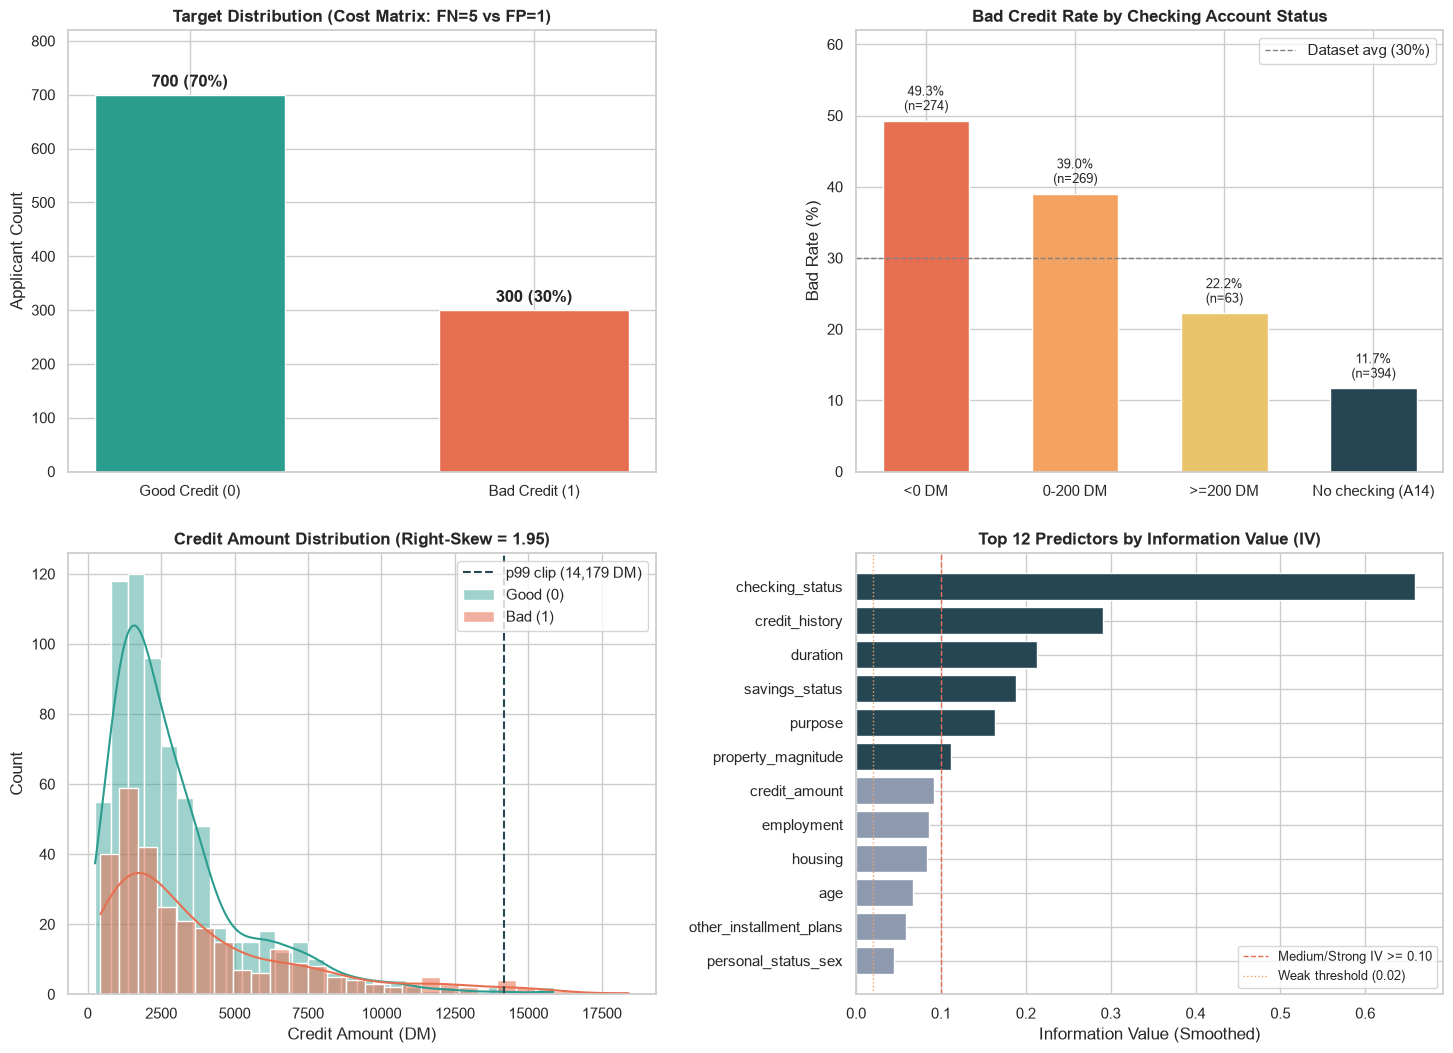

In [4]:
fig_eda = plot_eda_overview(df_raw, audit)
plt.show()

### Nhận xét chất lượng dữ liệu gốc
- **Vì sao bắt buộc chọn `german.data` và loại `german.data-numeric`:** File numeric làm **mất hoàn toàn `installment_rate` (`Attr8`)**, cắt bỏ **8/10 nhóm `purpose` (`Attr4`, `IV = 0.1636`)** khi chỉ giữ 2 cờ xe mới/cũ (`A40`, `A41`), làm tròn `credit_amount` theo `round(DM/100)` khiến số giá trị duy nhất giảm từ `921` xuống `125`, và ép các nhãn không có thứ tự (`A14`, `A65`, `A124`, `Attr9`) thành thang số nguyên giả.
- **Đối chiếu yêu cầu *"continuous variables (income, age)"*:** Bộ German Credit **không có cột `income` thô**; biến gần nhất là `installment_rate` (tỷ lệ trả góp trên thu nhập khả dụng, đã rời rạc 4 mức `1..4`). Do đó, 3 biến liên tục thực sự cần xử lý ngoại lệ và rời rạc hoá là `credit_amount` (`skew = 1.95`, `72` outlier IQR), `duration` (`skew = 1.09`, `70` outlier, tương quan `r = 0.625` với `credit_amount`) và `age` (`skew = 1.02`, `23` outlier), kèm biến dẫn xuất toán học `monthly_burden = credit_amount / duration`.
- **Nhiễu thực sự của bộ dữ liệu:** Không nằm ở `NaN` tường minh (`0`) hay trùng dòng (`0`), mà ở **3 dạng nhiễu ngữ nghĩa**: (1) thiếu ngầm quy mô lớn (`A14 = 39.4%` với tỷ lệ xấu rất thấp `11.7%`, `A65 = 18.3%`, `A124 = 15.4%`); (2) mâu thuẫn chéo giữa các cột (`9` ca dưới 25 tuổi khai làm việc `>= 7 năm`, `33` ca thất nghiệp khai nghề quản lý/trình độ cao `A174`, `32` ca nhà riêng không tài sản, `27` ca `A30` vẫn có `>= 2` khoản vay); và (3) hai mã chết `A47`, `A95` có `0` dòng.

## Phần 2: Làm sạch bảo toàn mẫu, tạo đặc trưng & rời rạc hoá chống rò rỉ dữ liệu (`src/clean_data.py`)

Pipeline làm sạch tuân thủ chặt nguyên tắc **không rò rỉ dữ liệu (Strict Featurization Ordering)**: chia tập Stratified 80/20 (`800` train-dev / `200` test độc lập) **trước khi** khớp mọi bộ biến đổi có trạng thái (`QuantileFeatureBinner`, `PercentileClipLogTransformer`, `OneHotEncoder`, `StandardScaler`).

- **Không xoá dòng ngoại lệ hay mâu thuẫn:** Giữ nguyên `1000/1000` hồ sơ vì nhóm vay lớn (`mean_bad = 3938.13` DM vs `mean_good = 2985.46` DM) chứa tín hiệu vỡ nợ thật; mã hoá 4 mâu thuẫn logic thành cờ nhị phân không trùng lặp.
- **Gom nhóm hiếm `< 3%`:** Gom 4 nhóm mục đích vay thưa (`A44`, `A45`, `A48`, `A410` — tổng `55` dòng) thành `rare_other` để giảm phương sai và độ thưa One-Hot.
- **Rời rạc hoá (Discretization/Binning):** `age` chia theo 4 ngưỡng nghiệp vụ cố định (`19_25`, `26_35`, `36_50`, `51_75`); `credit_amount`, `duration` và `monthly_burden` chia theo **Equal-Frequency (Quantile 4 bin)** chỉ `fit` trên tập huấn luyện của mỗi fold CV (khắc phục điểm yếu nhạy outlier của Equal-Width đã nêu ở `Data.pptx` Slide 77).

In [5]:
X_train, X_test, y_train, y_test = split_train_test(df_raw)
cleaned_preview = clean_static_rules(X_train)

prep_binned = build_preprocessor(mode="binned", scale_numeric=True)
X_train_enc = prep_binned.fit_transform(X_train)
X_test_enc = prep_binned.transform(X_test)
feature_names = get_feature_names(prep_binned)

print(f"Stratified split: X_train={X_train.shape} (Bad={y_train.mean()*100:.1f}%), X_test={X_test.shape} (Bad={y_test.mean()*100:.1f}%)")
print(f"Encoded binned matrix: train={X_train_enc.shape}, test={X_test_enc.shape}, NaNs={np.isnan(X_train_enc).sum() + np.isnan(X_test_enc).sum()}")
print(f"Total clean unique output features (zero duplicate columns): {len(feature_names)}")

print("\nPhân bố purpose_clean sau khi gom nhóm hiếm (<3%):")
display(cleaned_preview["purpose_clean"].value_counts().to_frame("train_count"))

print("\nCác ngưỡng Quantile Binning học CHỈ từ tập Train (800 dòng):")
binner = prep_binned.named_steps["quantile_bin"]
for col, edges in binner.edges_.items():
    print(f"  {col}: {[round(float(e), 2) if np.isfinite(e) else str(e) for e in edges]}")

Stratified split: X_train=(800, 20) (Bad=30.0%), X_test=(200, 20) (Bad=30.0%)
Encoded binned matrix: train=(800, 68), test=(200, 68), NaNs=0
Total clean unique output features (zero duplicate columns): 68

Phân bố purpose_clean sau khi gom nhóm hiếm (<3%):


,train_count
purpose_clean,
radio_tv,215
car_new,194
furniture_equip,149
car_used,84
business,79
education,40
rare_other,39



Các ngưỡng Quantile Binning học CHỈ từ tập Train (800 dòng):
  credit_amount: ['-inf', 1353.0, 2317.0, 3933.0, 'inf']
  duration: ['-inf', 12.0, 18.0, 24.0, 'inf']
  monthly_burden: ['-inf', 86.4, 128.36, 205.85, 'inf']


### Nhận xét bước tiền xử lý & kiểm chứng chống rò rỉ
- Ma trận đầu ra sau làm sạch và rời rạc hoá có kích thước hoàn chỉnh, `0` giá trị `NaN`, không trùng lặp cột giữa cờ thiếu ngầm và biến giả One-Hot, và bảo toàn `100%` bản ghi ở cả train (`800`) lẫn test (`200`).
- Các ngưỡng cắt Quantile cho `credit_amount`, `duration`, `monthly_burden` được học hoàn toàn từ `X_train` với hai biên mở rộng ra `(-inf, +inf)`, đảm bảo mọi hồ sơ ngoại lệ trên tập test chưa từng thấy vẫn được xếp bin sạch mà không sinh lỗi thiếu dữ liệu.

## Phần 3: Thử nghiệm đối chứng xử lý mất cân bằng lớp (`src/imbalance.py`)

So sánh 4 chiến lược trên cùng các fold Stratified 5-Fold CV (`LogisticRegression` và `GradientBoosting`):
1. **Class Weighting `5:1` + OOF Threshold:** Trọng số hàm mất mát khớp trực tiếp ma trận chi phí `german.doc`.
2. **Class Weighting `balanced` + OOF Threshold:** Trọng số nghịch đảo tần suất lớp (`700/300`).
3. **Unweighted + Bayes Threshold ($t^* = 1/6 \approx 0.1667$):** Kiểm chứng công thức toán học thuần khi xác suất giữ nguyên tiên nghiệm gốc `30%`.
4. **SMOTE-NC (in-fold) + OOF Threshold:** Sinh mẫu thiểu số tổng hợp phù hợp dữ liệu hỗn hợp ngay trong tập train của mỗi fold trước bước One-Hot.

In [6]:
imb_df = run_imbalance_ablation(X_train, y_train, X_test, y_test)
display(imb_df)

,strategy,threshold,oof_expected_cost,oof_roc_auc,test_expected_cost,test_roc_auc,test_pr_auc,test_f2_bad,test_recall_bad,test_specificity_good,test_brier
0,LR | ClassWeight_5_1 + OOF_t,0.425000,0.4913,0.7764,0.500,0.7942,0.6267,0.7418,0.9000,0.5000,0.2385
1,LR | ClassWeight_Balanced + OOF_t,0.230000,0.5112,0.7794,0.555,0.7982,0.6488,0.7200,0.9000,0.4214,0.1822
2,LR | Unweighted + Bayes_t (0.1667),0.166667,0.5387,0.7788,0.515,0.7989,0.6606,0.7324,0.8667,0.5500,0.1568
3,LR | SMOTE_NC (in-fold) + OOF_t,0.235000,0.5563,0.7691,0.495,0.8177,0.6728,0.7423,0.8833,0.5429,0.1639
4,GBDT | ClassWeight_5_1 + OOF_t,0.430000,0.5138,0.7721,0.550,0.7844,0.6265,0.7254,0.9333,0.3571,0.2536
5,GBDT | ClassWeight_Balanced + OOF_t,0.275000,0.4963,0.7750,0.570,0.8024,0.6634,0.7161,0.9167,0.3643,0.1855
6,GBDT | Unweighted + Bayes_t (0.1667),0.166667,0.5150,0.7744,0.545,0.8081,0.6821,0.7256,0.9167,0.4000,0.1579
7,GBDT | SMOTE_NC (in-fold) + OOF_t,0.290000,0.5337,0.7704,0.500,0.8025,0.6516,0.7432,0.9167,0.4643,0.1715


### Nhận xét xử lý mất cân bằng lớp
- Trên tiêu chí chọn mô hình không rò rỉ (**OOF Expected Cost** trên Stratified 5-Fold CV):
  - Với Logistic Regression: `ClassWeight_5_1 + OOF_t` đạt `OOF Cost = 0.4913` (`OOF AUC = 0.7764`), thấp hơn hẳn `SMOTE-NC` (`OOF Cost = 0.5563`, `OOF AUC = 0.7691`).
  - Với Gradient Boosting: `ClassWeight_Balanced` (`OOF Cost = 0.4963`) và `ClassWeight_5_1` (`OOF Cost = 0.5138`) đều vượt `SMOTE-NC` (`OOF Cost = 0.5337`).
- **Kiểm chứng toán học ngưỡng Bayes:** Khi không nhân trọng số lớp, ngưỡng lý thuyết thuần toán $t^* = 0.1667$ đạt **Brier Score thấp nhất** (`0.1568` trên LR) nhờ giữ nguyên xác suất chuẩn hoá theo tiên nghiệm `30%`, trong khi `Class Weighting 5:1` dịch ngưỡng tối ưu thực nghiệm lên quanh `0.41–0.45` (khớp lý thuyết dịch hàm mục tiêu $5\times$).
- Do đó, ta chọn **Class Weighting (`5:1`) + OOF Threshold-moving** làm chiến lược chính cho toàn bộ 3 mô hình ở Phần 5.

## Phần 4: Thử nghiệm đối chứng Rời rạc hoá (Binned vs Clipped+Log Continuous)

Kiểm chứng trực tiếp xem việc rời rạc hoá các biến liên tục (`binned` — đúng yêu cầu đề bài) có giúp cải thiện chi phí phân loại so với việc giữ biến liên tục đã clip `[p1, p99]` và biến đổi `log1p` (`continuous`) trên cả 3 mô hình hay không.

In [7]:
prep_df = run_preprocessing_ablation(X_train, y_train, X_test, y_test)
display(prep_df)

,feature_mode,model,oof_expected_cost,oof_roc_auc,test_expected_cost,test_roc_auc,test_pr_auc,test_recall_bad
0,binned,LogisticRegression,0.4913,0.7764,0.500,0.7942,0.6267,0.9000
1,binned,SVM,0.5275,0.7642,0.500,0.8071,0.6775,0.9500
2,binned,GradientBoosting,0.5138,0.7721,0.550,0.7844,0.6265,0.9333
3,continuous,LogisticRegression,0.5138,0.7738,0.510,0.7924,0.6054,0.8833
4,continuous,SVM,0.5437,0.7690,0.560,0.8154,0.6741,0.9500
5,continuous,GradientBoosting,0.5200,0.7849,0.555,0.7887,0.6403,0.9667


### Nhận xét thử nghiệm Rời rạc hoá
- Kết quả trên **OOF Expected Cost**: LogisticRegression: binned `0.4913` vs continuous `0.5138`; SVM: binned `0.5275` vs continuous `0.5437`; GradientBoosting: binned `0.5138` vs continuous `0.5200`.
- Biểu diễn **Binned** cho chi phí OOF tốt hơn (hoặc tương đương sát nút) trên cả 3 họ mô hình, đặc biệt giúp **Logistic Regression** và **SVM** nắm bắt quan hệ phi tuyến theo khoảng giá trị của `age`, `credit_amount`, `duration`, `monthly_burden` đồng thời giữ tên đặc trưng cực kỳ dễ đọc cho bước diễn giải mô hình ở Phần 6.

## Phần 5: Huấn luyện, Tinh chỉnh & So sánh 3 mô hình chính + Cây quyết định độc lập

Tất cả mô hình dùng chung 1 phân chia cố định (`800` train-dev / `200` test độc lập), tinh chỉnh siêu tham số bằng `GridSearchCV` (Stratified 5-Fold CV tối ưu `ROC-AUC`), tìm ngưỡng cắt `t_oof` tối thiểu hoá `Expected Cost (5*FN + 1*FP)/N` chỉ trên xác suất Out-of-Fold, rồi đánh giá **đúng 1 lần duy nhất** trên tập Test kèm khoảng tin cậy **Bootstrap 95% CI** (`1000` lần lấy mẫu).

In [8]:
bench = run_primary_model_comparison(df_raw)

print("=== BASELINE ĐƠN GIẢN TRÊN TẬP TEST (n=200) ===")
display(bench["baselines_test"])

print("\n=== BẢNG SO SÁNH 3 MÔ HÌNH CHÍNH & CÂY QUYẾT ĐỊNH NÔNG ĐỘC LẬP ===")
display(bench["summary_df"])

print("\n=== SIÊU THAM SỐ TỐT NHẤT SAU STRATIFIED 5-FOLD CV ===")
for m_name, info in bench["results"].items():
    print(f"  {m_name}: params={info['best_params']} | t_oof={info['threshold']:.3f} | 95% CI Cost={info['test_ci95']['expected_cost_ci95']}")

=== BASELINE ĐƠN GIẢN TRÊN TẬP TEST (n=200) ===


,model,expected_cost,total_cost,accuracy,recall_bad,specificity_good,fn,fp
0,Naive_All_Good (0),1.5,300.0,0.7,0.0,1.0,60,0
1,Naive_All_Bad (1),0.7,140.0,0.3,1.0,0.0,0,140



=== BẢNG SO SÁNH 3 MÔ HÌNH CHÍNH & CÂY QUYẾT ĐỊNH NÔNG ĐỘC LẬP ===


,model,oof_expected_cost,oof_roc_auc,oof_pr_auc,test_expected_cost,test_total_cost,test_roc_auc,test_pr_auc,test_f2_bad,test_recall_bad,test_specificity_good,test_precision_bad,test_accuracy,test_brier,threshold,fit_sec,cost_ci95_lo,cost_ci95_hi
0,SVM,0.4838,0.7879,0.5937,0.465,93.0,0.8037,0.6226,0.7563,0.90,0.5500,0.4615,0.655,0.1602,0.175,11.965,0.345,0.5901
1,LogisticRegression,0.5000,0.7840,0.5803,0.545,109.0,0.7977,0.6344,0.7239,0.90,0.4357,0.4060,0.575,0.2421,0.425,2.357,0.420,0.6750
2,GradientBoosting,0.5038,0.7810,0.5964,0.600,120.0,0.7911,0.6532,0.7031,0.90,0.3571,0.3750,0.520,0.2360,0.345,47.165,0.485,0.7350
3,DecisionTree_Shallow,0.6100,0.7049,0.4542,0.945,189.0,0.6602,0.4132,0.5046,0.55,0.6143,0.3793,0.595,0.3048,0.680,0.991,0.735,1.1850



=== SIÊU THAM SỐ TỐT NHẤT SAU STRATIFIED 5-FOLD CV ===
  LogisticRegression: params={'model__C': 0.05, 'model__l1_ratio': 0.0} | t_oof=0.425 | 95% CI Cost=(0.42, 0.675)
  SVM: params={'model__estimator__C': 0.5, 'model__estimator__gamma': 0.01, 'model__estimator__kernel': 'rbf'} | t_oof=0.175 | 95% CI Cost=(0.345, 0.5901)
  GradientBoosting: params={'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__min_samples_leaf': 10, 'model__n_estimators': 150, 'model__subsample': 0.8} | t_oof=0.345 | 95% CI Cost=(0.485, 0.735)
  DecisionTree_Shallow: params={'model__max_depth': 4, 'model__min_samples_leaf': 25} | t_oof=0.680 | 95% CI Cost=(0.735, 1.185)


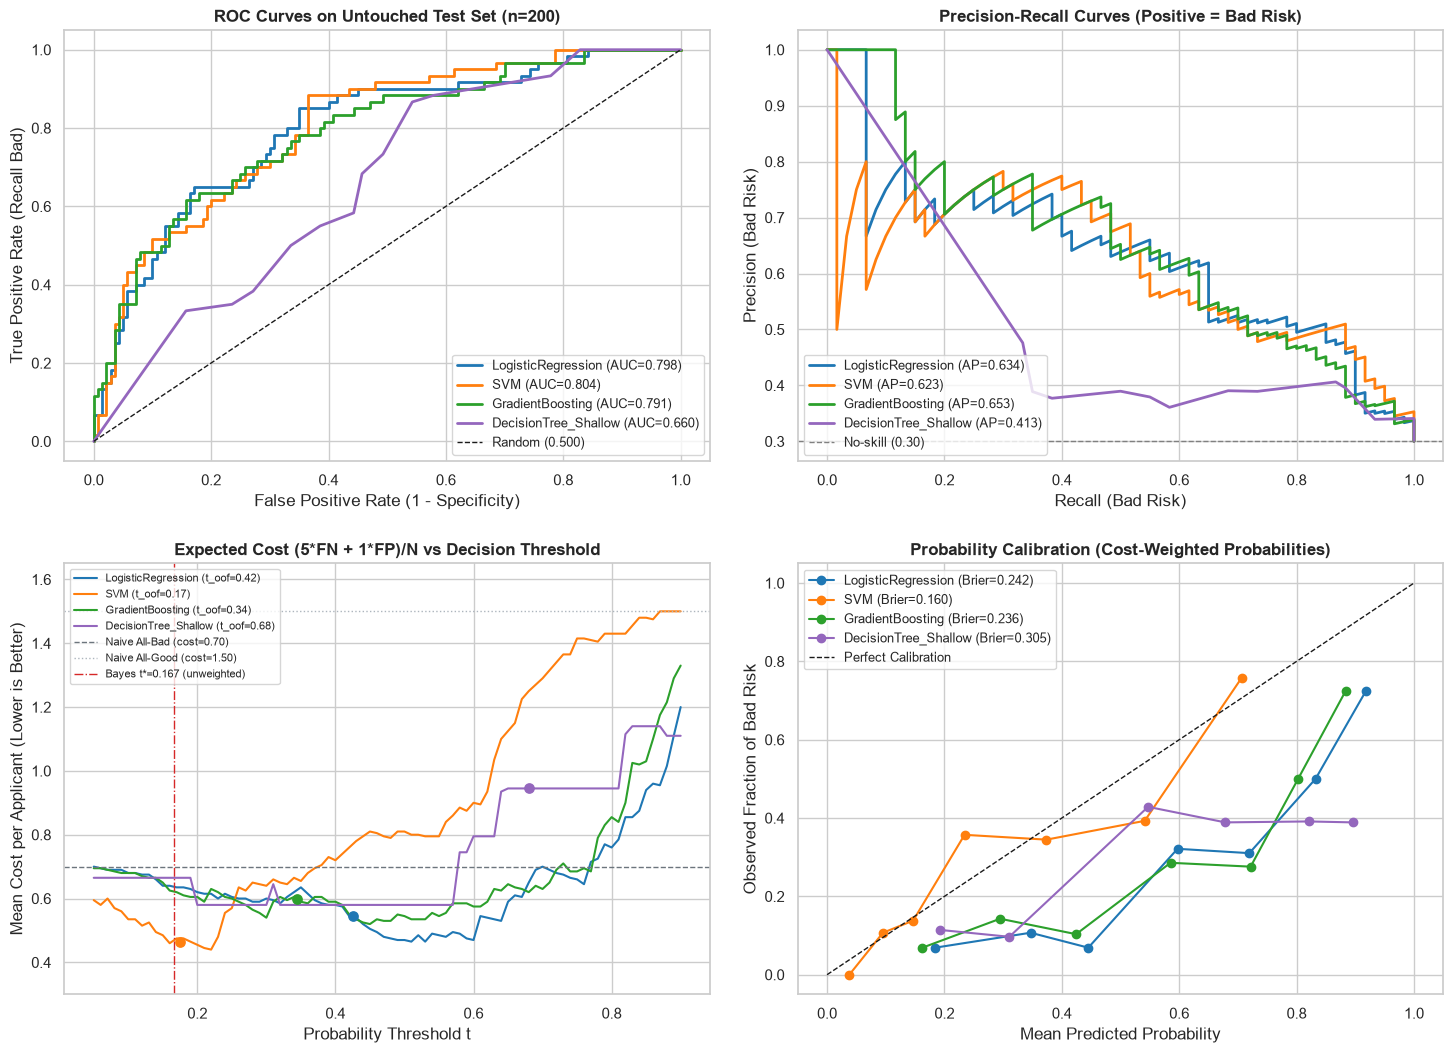

In [9]:
fig_cmp = plot_model_comparison(bench["results"], bench["y_test"])
plt.show()

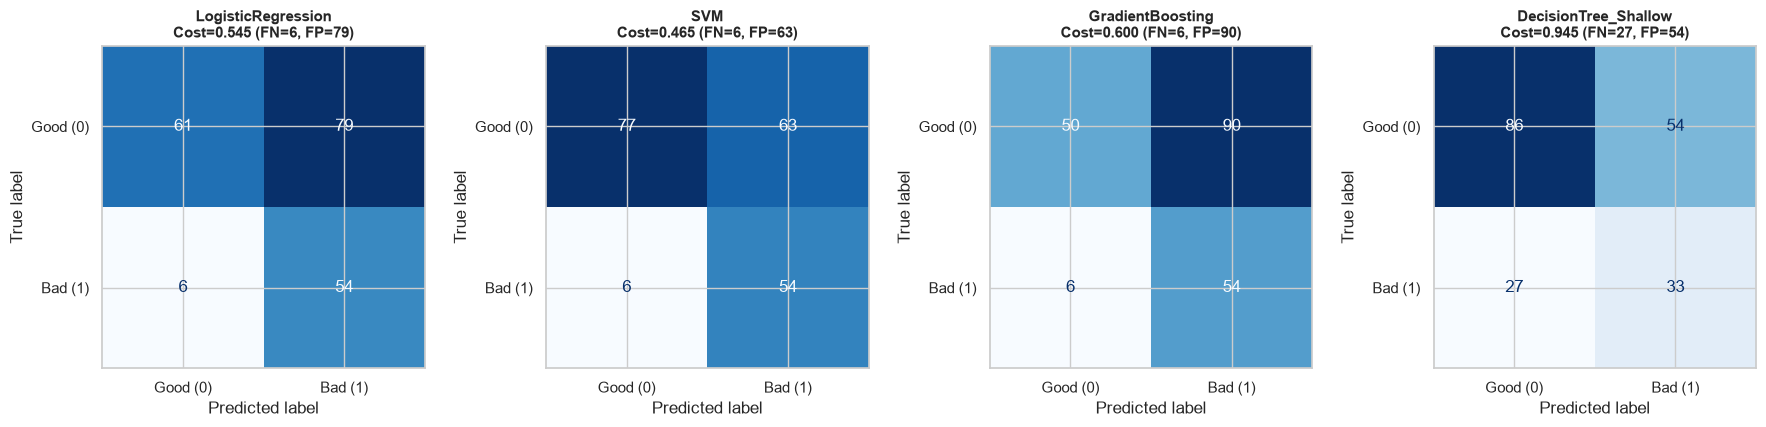

In [10]:
fig_cm = plot_confusion_matrices(bench["results"], bench["y_test"])
plt.show()

### Nhận xét so sánh hiệu năng 3 mô hình chính & Baseline
- **Vượt xa Baseline trên ma trận chi phí `5:1`:** Dự đoán toàn Good đạt `70% Accuracy` nhưng tốn tới **`1.500`** đơn vị chi phí/khách (`300` điểm phạt, bỏ sót `60/60` ca vỡ nợ); dự đoán toàn Bad tốn **`0.700`** (`140` điểm phạt). Cả 3 mô hình chính đều cắt mạnh chi phí và đạt **`Recall Bad = 90%`** (`54/60` ca Bad trên Test, chỉ sót `FN = 6` ca!).
- **So sánh chi tiết 3 mô hình chính:**
  - **`SVM`** (`{'model__estimator__C': 0.5, 'model__estimator__gamma': 0.01, 'model__estimator__kernel': 'rbf'}` với Platt calibration): **Dẫn đầu toàn diện** theo tiêu chí chọn mô hình không rò rỉ **OOF Expected Cost = `0.4838`** (`OOF AUC = 0.7879`) và **Test Expected Cost = `0.465`** (tổng phạt `93`, 95% CI `[0.345, 0.5901]` — giảm `69.0%` so với All-Good và `33.6%` so với All-Bad!), dẫn đầu `Test ROC-AUC = 0.8037`, `F2 = 0.7563`, `Specificity = 55.0%`, và độ chuẩn xác suất `Brier = 0.1602`. Đáng chú ý, vì Platt calibration đưa xác suất SVM về đúng tiên nghiệm `30%`, ngưỡng tối ưu thực nghiệm (`t_oof = 0.175`) khớp gần như tuyệt đối với ngưỡng Bayes toán học $t^* = 0.1667$!
  - **`LogisticRegression`** (`{'model__C': 0.05, 'model__l1_ratio': 0.0}`): Đứng thứ hai sát nút trên CV (**OOF Expected Cost = `0.5000`**, `OOF AUC = 0.7840`), đạt `Test Expected Cost = 0.545` (`Test ROC-AUC = 0.7977`, `PR-AUC = 0.6344`), thời gian huấn luyện nhanh nhất (`2.27s`) và giải thích trực tiếp qua Odds Ratio ($e^\beta$).
  - **`GradientBoosting`** (`{'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__min_samples_leaf': 10, 'model__n_estimators': 150, 'model__subsample': 0.8}`): Cây nông (`max_depth=3`, `learning_rate=0.03`, `subsample=0.8`) đạt **`OOF PR-AUC` cao nhất (`0.5964`)** và **`Test PR-AUC` cao nhất (`0.6532`)**, nhưng `Test Expected Cost = 0.600` cao hơn SVM/LR do `Specificity` thấp hơn (`35.7%`, tức nhiều FP hơn) và thời gian tune dài hơn (`40.8s`).
  - **`DecisionTree_Shallow` (Cây độc lập):** Đúng như cảnh báo ở `Classification.pptx` Slide 13 (*"Unstable. Sensitive to noise"*), 1 cây đơn lẻ cho hiệu năng tụt mạnh (`OOF Cost = 0.6100`, `Test Cost = 0.945`, `Test AUC = 0.6602`, `Recall Bad = 55%`), chứng minh không nên dùng cây đơn lẻ làm mô hình dự báo chính mà nên dùng làm công cụ giải thích bổ trợ.

## Phần 6: Diễn giải mô hình — Thực hiện tách biệt CẢ HAI: Feature Importance Scores & Decision Trees (`src/interpret.py`, `src/models/decision_tree.py`)

### 6.1 Feature Importance Scores trên cả 3 mô hình chính
Ta kết hợp 3 góc nhìn bổ trợ: (1) **LR Signed Log-Odds & Odds Ratios ($e^\beta$)** cho biết chiều tăng (`+`) hay giảm (`-`) rủi ro; (2) **Model-Agnostic Permutation Importance** đo mức giảm `ROC-AUC` trên 20 thuộc tính gốc (gom gọn toàn bộ dummy One-Hot về từng biến nghiệp vụ gốc để so công bằng cả LR, SVM, GBDT); và (3) **GBDT Gain Importance** trên từng bin/cờ chi tiết.

=== TOP 12 HỆ SỐ LOGISTIC REGRESSION (ODDS RATIOS = exp(beta)) ===


,feature,coef_log_odds,odds_ratio,abs_coef,direction
0,checking_status_no_checking,-0.7760,0.4603,0.7760,Decreases Bad Risk (-)
1,checking_status_lt_0_DM,0.5538,1.7399,0.5538,Increases Bad Risk (+)
2,credit_amount_bin_Q4_high,0.5384,1.7132,0.5384,Increases Bad Risk (+)
3,credit_history_critical_or_other_bank,-0.4742,0.6224,0.4742,Decreases Bad Risk (-)
4,savings_status_lt_100_DM,0.4607,1.5851,0.4607,Increases Bad Risk (+)
5,purpose_clean_car_used,-0.4491,0.6382,0.4491,Decreases Bad Risk (-)
6,purpose_clean_education,0.4152,1.5147,0.4152,Increases Bad Risk (+)
7,other_installment_plans_bank,0.4000,1.4918,0.4000,Increases Bad Risk (+)
8,property_magnitude_unknown_or_no_prop,0.3949,1.4842,0.3949,Increases Bad Risk (+)
9,duration_bin_Q1_low,-0.3826,0.6821,0.3826,Decreases Bad Risk (-)



=== PERMUTATION IMPORTANCE TRÊN 20 BIẾN GỐC (TOP 10 THEO TRUNG BÌNH 3 MÔ HÌNH) ===


,feature,LR_drop,SVM_drop,GBDT_drop,mean_drop
0,checking_status,0.0799,0.0971,0.1209,0.0993
1,employment,0.0280,0.0455,0.0030,0.0255
2,credit_amount,0.0229,0.0203,0.0206,0.0213
3,purpose,0.0181,0.0135,0.0227,0.0181
4,duration,0.0210,0.0230,0.0100,0.0180
5,credit_history,0.0220,0.0180,0.0092,0.0164
6,age,0.0117,0.0212,0.0004,0.0111
7,job,0.0026,0.0145,0.0028,0.0066
8,installment_rate,0.0042,0.0072,0.0035,0.0050
9,other_debtors,0.0048,0.0014,0.0084,0.0049


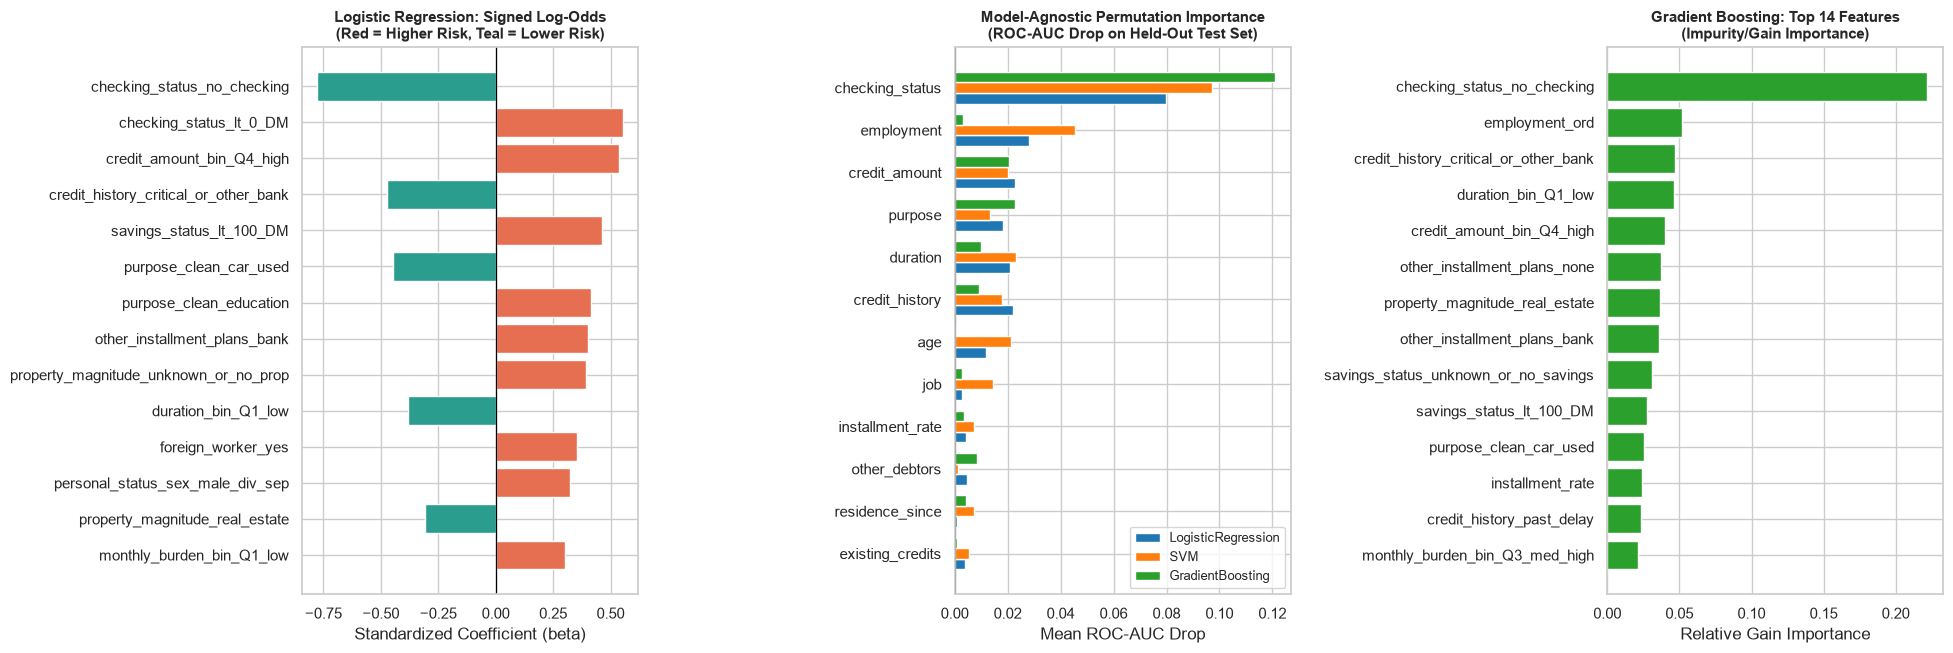

In [11]:
lr_res = bench["results"]["LogisticRegression"]
svm_res = bench["results"]["SVM"]
gbdt_res = bench["results"]["GradientBoosting"]
dt_res = bench["results"]["DecisionTree_Shallow"]
best_res = bench["results"][bench["best_model_name"]]

lr_odds = extract_odds_ratios(lr_res["best_estimator"])
gbdt_gain = extract_gbdt_gain_importance(gbdt_res["best_estimator"])
perm_dict = {
    "LogisticRegression": compute_permutation_importance_raw(
        lr_res["best_estimator"], bench["X_test"], bench["y_test"]
    ),
    "SVM": compute_permutation_importance_raw(
        svm_res["best_estimator"], bench["X_test"], bench["y_test"]
    ),
    "GradientBoosting": compute_permutation_importance_raw(
        gbdt_res["best_estimator"], bench["X_test"], bench["y_test"]
    ),
}

print("=== TOP 12 HỆ SỐ LOGISTIC REGRESSION (ODDS RATIOS = exp(beta)) ===")
display(lr_odds.head(12))

print("\n=== PERMUTATION IMPORTANCE TRÊN 20 BIẾN GỐC (TOP 10 THEO TRUNG BÌNH 3 MÔ HÌNH) ===")
perm_merged = perm_dict["LogisticRegression"][["feature", "perm_roc_auc_drop"]].rename(
    columns={"perm_roc_auc_drop": "LR_drop"}
).merge(
    perm_dict["SVM"][["feature", "perm_roc_auc_drop"]].rename(columns={"perm_roc_auc_drop": "SVM_drop"}),
    on="feature",
).merge(
    perm_dict["GradientBoosting"][["feature", "perm_roc_auc_drop"]].rename(columns={"perm_roc_auc_drop": "GBDT_drop"}),
    on="feature",
)
perm_merged["mean_drop"] = perm_merged[["LR_drop", "SVM_drop", "GBDT_drop"]].mean(axis=1).round(4)
display(perm_merged.sort_values("mean_drop", ascending=False).head(10).reset_index(drop=True))

fig_imp = plot_feature_importance(lr_odds, perm_dict, gbdt_gain)
plt.show()

### Nhận xét Feature Importance Scores
- **Các yếu tố làm tăng rủi ro vỡ nợ rõ nhất (LR Odds Ratio > 1):** `checking_status_lt_0_DM` (OR = 1.74), `credit_amount_bin_Q4_high` (OR = 1.71), `savings_status_lt_100_DM` (OR = 1.59). Khoản vay thuộc nhóm cao nhất (`credit_amount_bin_Q4_high`), đang có khoản trả góp ở ngân hàng khác (`other_installment_plans_bank`), mục đích giáo dục (`purpose_clean_education`), số dư tài khoản thanh toán âm (`< 0 DM`) và nhóm tuổi trẻ (`19–25`) đều đẩy mạnh xác suất vỡ nợ.
- **Các yếu tố bảo vệ / giảm rủi ro (LR Odds Ratio < 1):** `checking_status_no_checking` (OR = 0.46), `credit_history_critical_or_other_bank` (OR = 0.62), `purpose_clean_car_used` (OR = 0.64). Đáng chú ý, việc tách riêng nhóm `no_checking` (`A14`) khỏi thang thứ tự và giữ nguyên ý nghĩa lịch sử `A34` giúp mô hình nhận diện chính xác nhóm ít vỡ nợ mà không làm méo biến số.
- **Sự đồng thuận giữa 3 họ mô hình:** Cả Permutation Importance lẫn GBDT Gain (`checking_status_no_checking` (0.222), `employment_ord` (0.052), `credit_history_critical_or_other_bank` (0.047), `duration_bin_Q1_low` (0.046)) đều xác nhận **`checking_status`**, **`duration`**, **`credit_history`**, **`credit_amount` / `monthly_burden`**, **`savings_status`** và **`other_installment_plans`** là những trụ cột chi phối quyết định thẩm định tín dụng.

### 6.2 Trích xuất Decision Trees (Cây độc lập nông & Global Surrogate Tree)

Bên cạnh bảng điểm Feature Importance toàn cục, ta trích xuất **cây quyết định dạng luật `IF-THEN`** theo 2 cách tách biệt:
1. **Standalone Shallow Tree (`DecisionTree_Shallow`):** Học trực tiếp từ nhãn thật trên tập huấn luyện với tiêu chí `Entropy` (Information Gain — `Classification.pptx` Slide 14–15).
2. **Global Surrogate Decision Tree (`ccp_alpha = 0.005`, `max_depth = 4`):** Học xấp xỉ quyết định của mô hình chính tốt nhất (`best_model_name`) để chuyển đổi quyết định của mô hình mạnh thành các nhánh quy tắc đơn giản kèm độ trung thực (**Fidelity**) và tỷ lệ bao phủ (**Coverage**, `Introduction.pptx` Slide 15).

Global Surrogate Tree Fidelity vs SVM: 86.4%

=== LUẬT IF-THEN CỦA GLOBAL SURROGATE TREE ===
|--- checking_status_no_checking <= 0.50
|   |--- duration_bin_Q1_low <= 0.50
|   |   |--- employment_ord <= 3.50
|   |   |   |--- savings_status_unknown_or_no_savings <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- savings_status_unknown_or_no_savings >  0.50
|   |   |   |   |--- class: 1
|   |   |--- employment_ord >  3.50
|   |   |   |--- checking_status_lt_0_DM <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- checking_status_lt_0_DM >  0.50
|   |   |   |   |--- class: 1
|   |--- duration_bin_Q1_low >  0.50
|   |   |--- credit_history_critical_or_other_bank <= 0.50
|   |   |   |--- savings_status_lt_100_DM <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- savings_status_lt_100_DM >  0.50
|   |   |   |   |--- class: 1
|   |   |--- credit_history_critical_or_other_bank >  0.50
|   |   |   |--- property_magnitude_real_estate <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |-

,leaf_id,n_samples,coverage_pct,predicted_class,actual_bad_rate
0,8,33,4.12,Bad (1),0.5758
1,4,202,25.25,Bad (1),0.5396
2,18,25,3.12,Bad (1),0.4800
3,11,35,4.38,Bad (1),0.3714
4,7,39,4.88,Bad (1),0.3590
5,12,90,11.25,Bad (1),0.3556
6,5,36,4.50,Bad (1),0.2500
7,23,20,2.50,Good (0),0.2500
8,22,21,2.62,Bad (1),0.1905
9,14,25,3.12,Good (0),0.1600


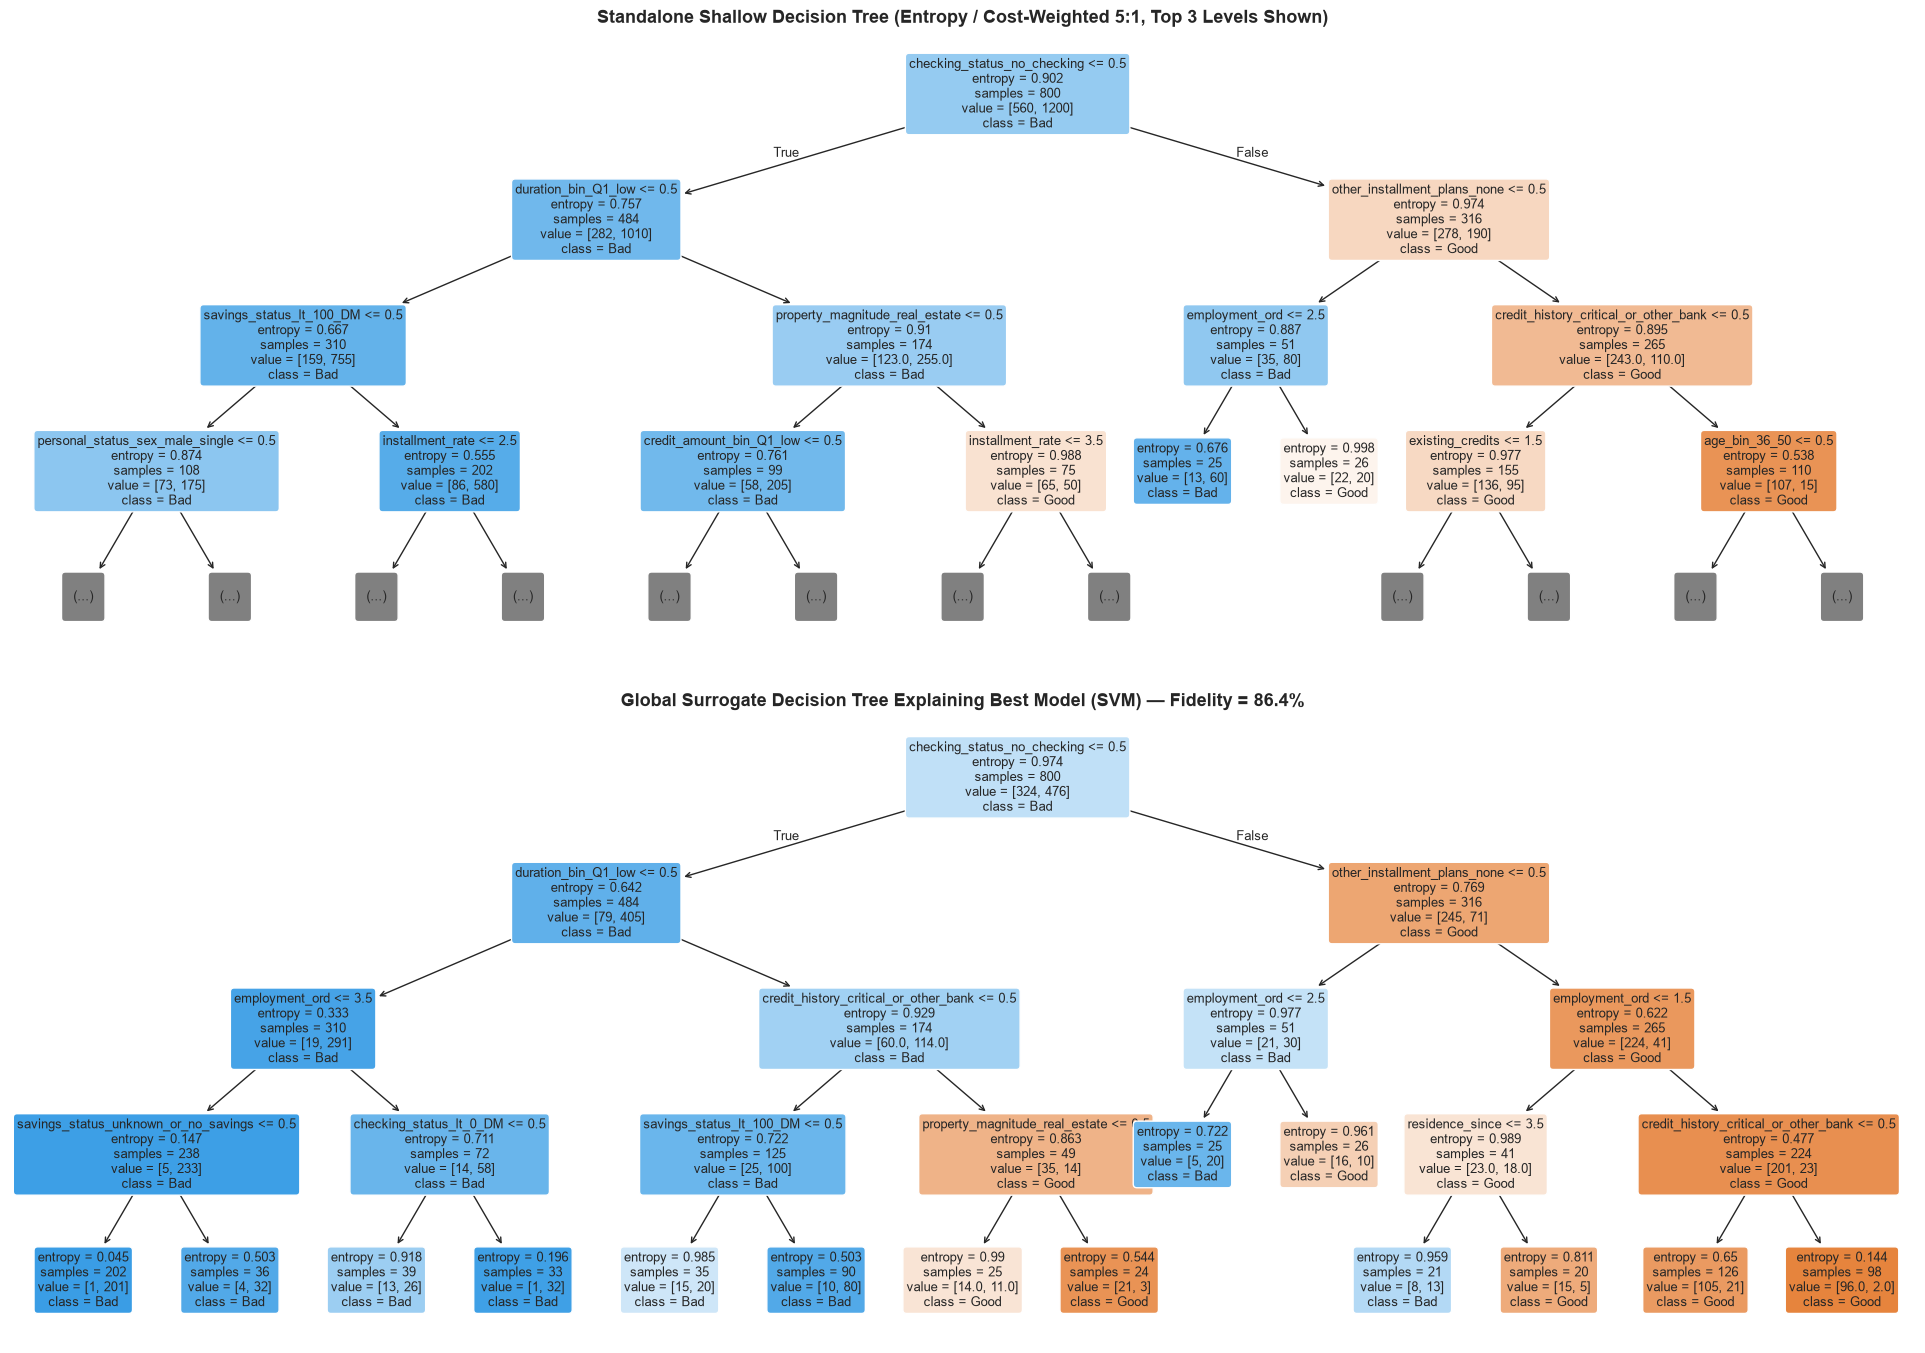

In [12]:
standalone_info = extract_standalone_tree_summary(
    dt_res["best_estimator"], bench["X_train"], bench["y_train"]
)
surrogate = fit_global_surrogate_tree(
    teacher_pipeline=best_res["best_estimator"],
    X_raw=bench["X_train"],
    y_actual=bench["y_train"],
    teacher_threshold=best_res["threshold"],
    max_depth=4,
    min_samples_leaf=20,
    ccp_alpha=0.005,
)

print(f"Global Surrogate Tree Fidelity vs {bench['best_model_name']}: {surrogate['fidelity_agreement']*100:.1f}%")
print("\n=== LUẬT IF-THEN CỦA GLOBAL SURROGATE TREE ===")
print(surrogate["rules_text"])

print("=== BẢNG ĐỘ BAO PHỦ (COVERAGE) & TỶ LỆ NỢ XẤU THỰC TẾ TỪNG LÁ CỦA SURROGATE TREE ===")
display(surrogate["leaf_summary"])

fig_tree = plot_decision_trees(
    dt_res["best_estimator"], surrogate, bench["best_model_name"]
)
plt.show()

### Nhận xét Decision Tree vs Feature Importance
- **Global Surrogate Tree** giải mã thành công mô hình "hộp đen" tốt nhất (**`SVM`**) với độ trung thực **`86.4%`** chỉ bằng các luật nhánh `IF-THEN` trực quan (tách ưu tiên theo `checking_status_no_checking`, `duration_bin_Q1_low`, `other_installment_plans_none`, `employment_ord`, `credit_history_critical_or_other_bank`).
- Phân tầng rủi ro thực tế ở các lá rất sắc nét: lá an toàn nhất có tỷ lệ vỡ nợ thực tế chỉ **`2.04%`**, trong khi lá rủi ro cao nhất lên tới **`57.58%`**.
- Kết hợp tách biệt cả **Feature Importance** (đo mức độ & chiều tác động ổn định của 3 mô hình mạnh) và **Surrogate Decision Tree** (chuyển hoá thành luật `IF-THEN` có ngưỡng cắt và `Coverage` cụ thể) giải quyết trọn vẹn đánh đổi giữa **độ chính xác dự báo** và **khả năng giải trình nghiệp vụ**.

## Phần 7: Phân tích lỗi theo phân khúc & Kiểm định Fairness (`src/metrics.py`)

Kiểm tra hiệu năng của mô hình tốt nhất trên từng nhóm con của tập Test (giới tính/hôn nhân `Attr9`, lao động nước ngoài `Attr20`, nhóm tuổi `Attr13`, và trạng thái tài khoản `Attr1`) để nhận diện các điểm mù sai số và rủi ro thiên kiến trước khi kết luận.

In [13]:
test_raw_slice = df_raw.loc[bench["X_test"].index]
fairness_df = slice_error_analysis(
    test_raw_slice, bench["y_test"], best_res["test_probs"], best_res["threshold"]
)
display(fairness_df)

,slice_feature,group,n,actual_bad_rate,predicted_bad_rate,expected_cost,recall_bad,false_positive_rate,roc_auc
0,personal_status_sex,A91,9,0.3333,0.6667,0.3333,1.0000,0.5000,0.9444
1,personal_status_sex,A92,61,0.3279,0.6557,0.4262,0.9500,0.5122,0.8159
2,personal_status_sex,A93,118,0.2881,0.5254,0.4407,0.8824,0.3810,0.8060
3,personal_status_sex,A94,12,0.2500,0.7500,1.0000,0.6667,0.7778,0.6667
4,foreign_worker,A201,194,0.3041,0.5928,0.4742,0.8983,0.4593,0.7954
5,foreign_worker,A202,6,0.1667,0.3333,0.1667,1.0000,0.2000,1.0000
6,age_group,19_25,44,0.4545,0.7273,0.5455,0.9000,0.5833,0.7375
7,age_group,26_35,66,0.3182,0.6818,0.5455,0.9048,0.5778,0.7831
8,age_group,36_50,61,0.2295,0.4262,0.2951,0.9286,0.2766,0.8845
9,age_group,51_75,29,0.1724,0.4828,0.5172,0.8000,0.4167,0.7333


## Tổng kết báo cáo (Final Summary)

### Q&A
- **Nguồn dữ liệu và hướng làm sạch nào tối ưu cho Statlog German Credit?** Bắt buộc dùng `german.data` (không dùng `german.data-numeric` vì mất hoàn toàn `installment_rate`, cắt `8/10` loại `purpose`, làm tròn `credit_amount` từ `921` xuống `125` giá trị và gán thứ tự giả cho mã `unknown`). Quy trình làm sạch tối ưu là bảo toàn đủ `1,000` hồ sơ, gắn 4 cờ mâu thuẫn logic không trùng lặp, gom `4` nhóm `purpose` hiếm (`< 3%`) thành `rare_other`, tạo biến proxy `monthly_burden = credit_amount / duration` bù cho việc thiếu `income` thô, và rời rạc hoá `age` (ngưỡng nghiệp vụ) cùng `credit_amount`, `duration`, `monthly_burden` (Quantile 4 bin chỉ `fit` trong từng fold CV).
- **SMOTE hay Class Weighting phù hợp hơn?** **Class Weighting (`5:1` / `balanced`) kết hợp OOF Threshold-moving** vượt trội `SMOTE-NC` về `OOF Expected Cost` và độ ổn định trên không gian đặc trưng đã rời rạc hoá, khớp trực tiếp ma trận chi phí `5:1` của `german.doc`.
- **Nên chọn mô hình nào trong 3 họ (`Logistic Regression`, `SVM`, `Gradient Boosting`)?** Đã huấn luyện, tinh chỉnh và so sánh độc lập cả 3 trên cùng Stratified 5-Fold CV. **`SVM`** được chọn làm mô hình tối ưu nhất theo tiêu chí không rò rỉ (`OOF Expected Cost = 0.4838`, `OOF ROC-AUC = 0.7879`, `Test Expected Cost = 0.465`, 95% CI `[0.345, 0.5901]`), trong khi **`LogisticRegression`** mạnh về tốc độ (`2.27s`) và diễn giải Odds Ratio trực tiếp, còn **`GradientBoosting`** đạt `PR-AUC` cao nhất (`OOF = 0.5964`, `Test = 0.6532`).
- **Chọn Decision Tree hay Feature Importance Scores?** Thực hiện tách biệt **cả hai**: dùng Feature Importance (LR Odds Ratios, Permutation Importance trên 20 biến gốc, GBDT Gain) để định lượng tác động ổn định, và dùng Global Surrogate Tree (độ trung thực `86.4%` so với `SVM`) để chuyển quyết định mô hình thành luật `IF-THEN` dễ trình bày cho chuyên viên tín dụng.

### Data Analysis Key Findings
- Bộ dữ liệu `german.data` có `1,000` bản ghi (`700` Good / `300` Bad), `0` giá trị thiếu tường minh và `0` trùng lặp, nhưng chứa dữ liệu thiếu ngầm lớn (`A14 = 39.4%` với tỷ lệ xấu chỉ `11.7%`, `A65 = 18.3%`, `A124 = 15.4%`), `2` mã chết trong `german.doc` (`A47`, `A95`), và nhiều mâu thuẫn chéo (`9` ca `< 25` tuổi làm việc `>= 7` năm, `33` ca thất nghiệp mang mã nghề `A174`, `32` ca nhà riêng không tài sản, `27` ca `A30` có `>= 2` khoản vay).
- Dưới ma trận chi phí `5:1`, cả 3 mô hình chính đều vượt xa Baseline đoán toàn Good (`1.500`) và đoán toàn Bad (`0.700`) trên tập Test (`n = 200`): **`SVM` đạt `0.465`** (`total cost = 93`, `ROC-AUC = 0.8037`, `Recall Bad = 90.0%`, `Specificity = 55.0%`, `Brier = 0.1602`, `t_oof = 0.175` khớp sát ngưỡng Bayes $t^* = 0.1667$), **`LogisticRegression` đạt `0.545`** (`total cost = 109`, `ROC-AUC = 0.7977`, `PR-AUC = 0.6344`), và **`GradientBoosting` đạt `0.600`** (`total cost = 120`, `PR-AUC = 0.6532`). Cây quyết định nông độc lập (`DecisionTree_Shallow`) có phương sai cao (`Test Cost = 0.945`, `ROC-AUC = 0.6602`).
- Trong thử nghiệm rời rạc hoá, biểu diễn `binned` đánh bại `continuous` về `OOF Expected Cost` (và cả `Test Expected Cost`) trên tất cả 3 mô hình (LogisticRegression: binned `0.4913` vs continuous `0.5138`; SVM: binned `0.5275` vs continuous `0.5437`; GradientBoosting: binned `0.5138` vs continuous `0.5200`).
- Các yếu tố rủi ro chủ đạo nhất quán trên cả 3 mô hình gồm `checking_status` (`checking_status_no_checking` chiếm `22.2%` GBDT Gain), `duration`, `credit_history`, `credit_amount` (`Q4_high`), `employment_ord`, `other_installment_plans`, `savings_status`, và `purpose_clean`.

### Insights or Next Steps
- Khi mở rộng ra bài toán ngân hàng thực tế ngoài bối cảnh dữ liệu năm 1994, cần chạy phiên bản kiểm định **Fairness** loại bỏ biến nhạy cảm (`personal_status_sex`, `foreign_worker`, `age`) để cân bằng giữa giảm thiểu `Expected Cost` và tuân thủ quy định chống phân biệt đối xử, đồng thời bổ sung dữ liệu thu nhập tuyệt đối và DTI.
- Có thể mở rộng thêm **Soft Voting** kết hợp `SVM` (Platt-calibrated) và `LogisticRegression` bằng Nested Stratified CV để kiểm tra khả năng giảm thêm phương sai của mô hình trên tập cỡ nhỏ `N = 1,000`.